In [2]:
import sys
sys.path.append("..")

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from clean_data import feature_engineering

In [3]:
df= pd.read_csv("../data/austin/raw/aac_intakes_outcomes.csv")

In [4]:
df = feature_engineering(df)

In [5]:
df["outcome_type"].value_counts(normalize=True)*100
#najczęstszy outcome to Adoption, klasy nie są zbalansowane, dlatego accuracy nie będzie odpowiednią metryką
#lepiej wykorzystać f1-score jako główną metrykę i analizę wyników dla każdej klasy osobno, aby ocenić skuteczność dla
#przypadków takich jak death czy też transfer

outcome_type
Adoption           46.449549
Transfer           29.039241
Return to Owner    20.268593
Death               4.242616
Name: proportion, dtype: float64

<Axes: xlabel='outcome_type'>

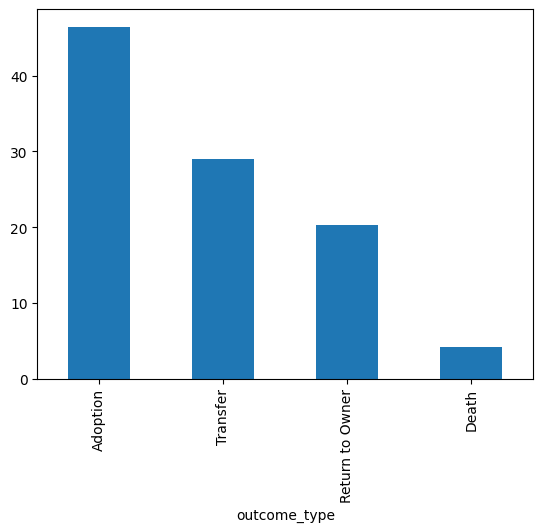

In [56]:
df["outcome_type"].value_counts(normalize=True).mul(100).plot(kind="bar")

In [57]:
df["intake_type"].value_counts(normalize=True)*100

#dominuje stray - bezpańskie, schronisko przyjmuje głownie zwierzęta bez właściciela
#intake_type może wpływać na outcome

#wildlife - usunąć wirsze - euthanasia_request 

intake_type
Stray              72.837821
Owner Surrender    20.485034
Public Assist       6.677145
Name: proportion, dtype: float64

In [58]:
df["intake_condition"].value_counts(normalize=True)*100
#większość zwierząt ma intake_condition = 'normal' 
#stan zwierzaka wpływa na outcome i może być istotną cechą w modelu

intake_condition
Normal     90.198674
Injured     4.359515
Sick        2.673340
Nursing     2.017069
Other       0.751403
Name: proportion, dtype: float64

<Axes: xlabel='outcome_type', ylabel='age_group'>

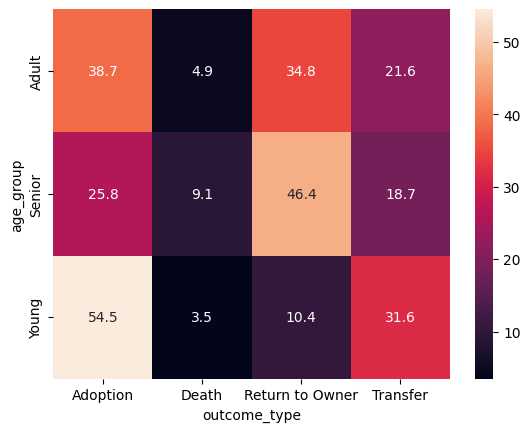

In [87]:
age_outcome = pd.crosstab(df["age_group"], df["outcome_type"], normalize="index").mul(100).round(2)

sns.heatmap(
    age_outcome,
    annot=True,
    fmt=".1f",
)

<Axes: xlabel='outcome_type', ylabel='days_in_shelters'>

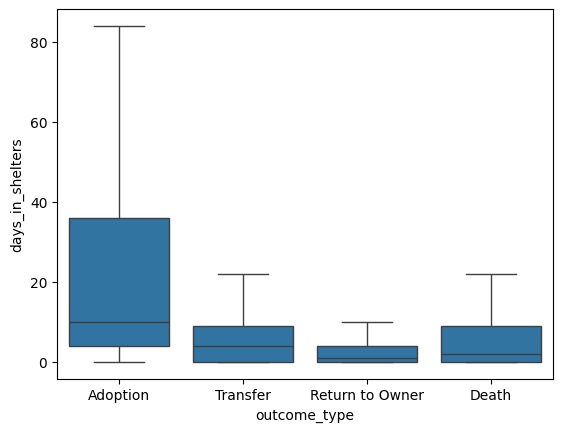

In [ ]:
sns.boxplot(data=df, x="outcome_type", y = "days_in_shelters",
            order=["Adoption","Transfer","Return to Owner","Death"],
            showfliers=False)

#adoption – animals placed for adoption; median = 10 days
#adoptions vary significantly
#transfer – 3 days; faster than adoption
#return to owner – owners retrieve their animals quickly

#length of stay varies depending on the outcome

#time_in_shelter depends on the outcome; the number of days in the shelter is a highly characteristic feature
#however, it functions as a counter tracking the time from intake to the final outcome

In [64]:
outcome_ohe = pd.get_dummies(df["outcome_type"], prefix="outcome")
num_cols = df.select_dtypes(include=["number"]).columns

<Axes: >

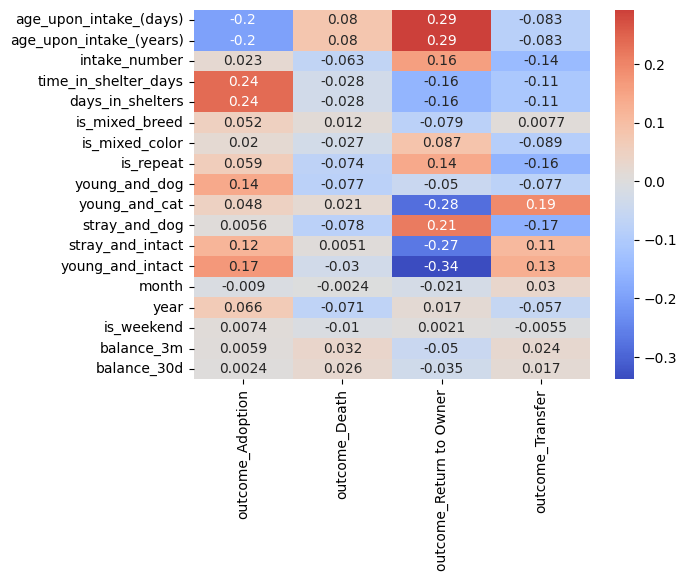

In [65]:
from scipy.stats import pointbiserialr

corr_results = pd.DataFrame(index=num_cols, columns=outcome_ohe.columns)

for outcome in outcome_ohe.columns: 
    for col in num_cols: 
        corr, p = pointbiserialr(outcome_ohe[outcome], df[col])
        corr_results.loc[col, outcome] = corr

corr_results = corr_results.astype(float)
sns.heatmap(corr_results, annot=True, cmap="coolwarm", center=0)

In [66]:
corr_results["outcome_Adoption"].sort_values(ascending=False)
#młode psy są częsciej adoptowane, starsze zwierzęta rzadziej (na podstawie korelacji)
#dzikie zwierzęta prawie nigdy nie są adoptowane

days_in_shelters           0.237119
time_in_shelter_days       0.236460
young_and_intact           0.169788
young_and_dog              0.141154
stray_and_intact           0.116921
year                       0.066054
is_repeat                  0.058948
is_mixed_breed             0.052254
young_and_cat              0.047610
intake_number              0.023491
is_mixed_color             0.020110
is_weekend                 0.007376
balance_3m                 0.005911
stray_and_dog              0.005648
balance_30d                0.002418
month                     -0.008959
age_upon_intake_(days)    -0.195605
age_upon_intake_(years)   -0.195605
Name: outcome_Adoption, dtype: float64

In [67]:
corr_results["outcome_Transfer"].sort_values(ascending=False)
#młode koty częsciej trafiają do transferu (dodatnia korelacja z transferem)
#bezpańskie psy albo takie które wracają częsciej to mają ujemną korelację, rzadziej trafiają do transferu
#korelacje są umiarkowane


young_and_cat              0.193435
young_and_intact           0.130893
stray_and_intact           0.110131
month                      0.029653
balance_3m                 0.024249
balance_30d                0.017231
is_mixed_breed             0.007705
is_weekend                -0.005506
year                      -0.056870
young_and_dog             -0.077175
age_upon_intake_(years)   -0.083189
age_upon_intake_(days)    -0.083189
is_mixed_color            -0.088723
time_in_shelter_days      -0.109519
days_in_shelters          -0.110276
intake_number             -0.142179
is_repeat                 -0.160234
stray_and_dog             -0.165023
Name: outcome_Transfer, dtype: float64

In [68]:
corr_results["outcome_Death"].sort_values(ascending=False)
#wildlife and other - dzikie zwierzęta kończą śmiercią
#młode psy, bezpańskie, mieszańce mają mniejsze ryzyko eutanazji/śmierci 
#wiek praktycznie nie koreluje ze śmiercią liniowo

age_upon_intake_(years)    0.079598
age_upon_intake_(days)     0.079598
balance_3m                 0.031726
balance_30d                0.025627
young_and_cat              0.021295
is_mixed_breed             0.012350
stray_and_intact           0.005123
month                     -0.002359
is_weekend                -0.010201
is_mixed_color            -0.026892
days_in_shelters          -0.028379
time_in_shelter_days      -0.028491
young_and_intact          -0.029833
intake_number             -0.062643
year                      -0.071177
is_repeat                 -0.073591
young_and_dog             -0.077291
stray_and_dog             -0.077759
Name: outcome_Death, dtype: float64

In [69]:
corr_results["outcome_Return to Owner"].sort_values(ascending=False)
#Starsze zwierzęta mają wyższą korelację z Return to Owner - wiek wpływa na szansę powrotu do włąsciciela
#zwierzęta po raz kolejny trafiające do schroniska wracają do właściciela 
#młode koty rzadko mają właściciela

age_upon_intake_(years)    0.292714
age_upon_intake_(days)     0.292714
stray_and_dog              0.214097
intake_number              0.158952
is_repeat                  0.140509
is_mixed_color             0.086630
year                       0.016868
is_weekend                 0.002135
month                     -0.020506
balance_30d               -0.034823
balance_3m                -0.049963
young_and_dog             -0.050022
is_mixed_breed            -0.079115
time_in_shelter_days      -0.156307
days_in_shelters          -0.156340
stray_and_intact          -0.268012
young_and_cat             -0.282632
young_and_intact          -0.338563
Name: outcome_Return to Owner, dtype: float64

In [72]:
df['intake_type'].value_counts(normalize=True)

intake_type
Stray              0.726231
Owner Surrender    0.206195
Public Assist      0.067574
Name: proportion, dtype: float64

In [73]:
cat_cols = df.select_dtypes(include="object").columns.drop(["outcome_type", "wildlife_and_other",
                         "animal_type_Other", "intact_Unknown", "outcome_subtype",
                         "balance_7m", "time_in_shelter_days", "time_in_shelter",
                         "sex_upon_outcome", "age_upon_intake_(years)", "intake_datetime", "intake_date", 
                         "day_of_week", "month", 'year','is_weekend',"primary_breed_top_Other","intake_number","is_repeat", 
                         'date_of_birth', 'animal_type'], errors="ignore")

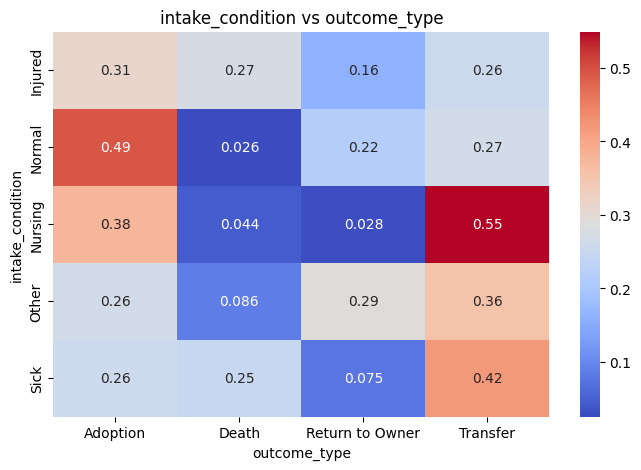

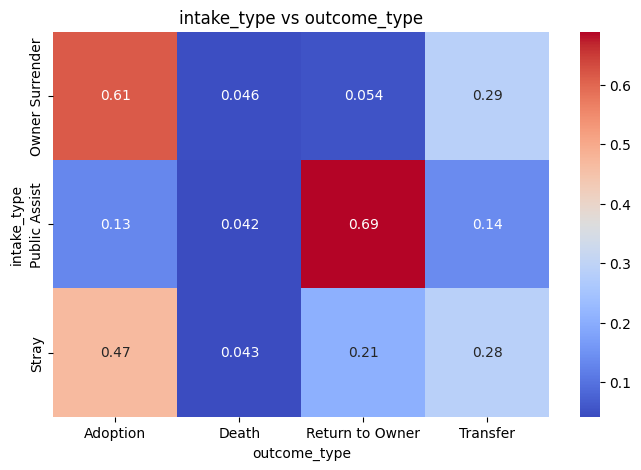

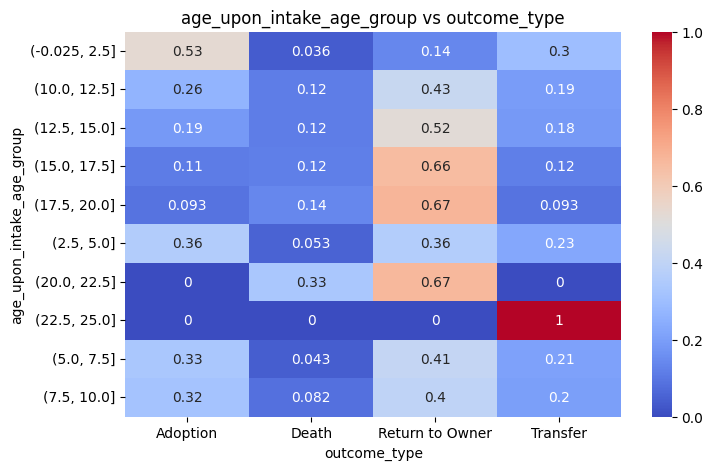

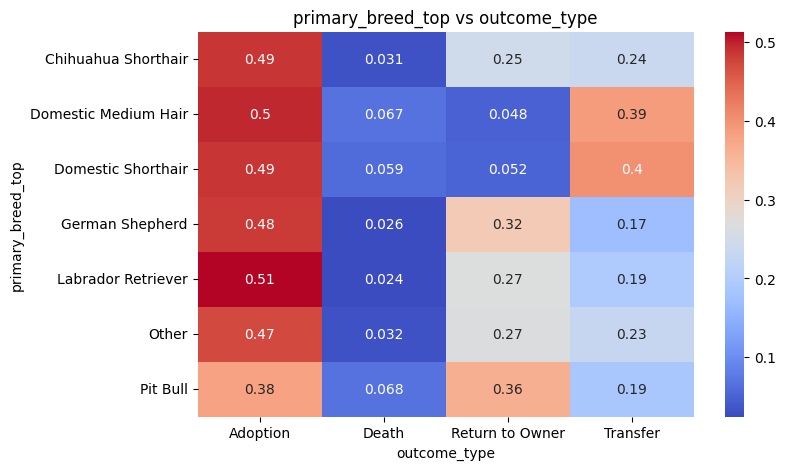

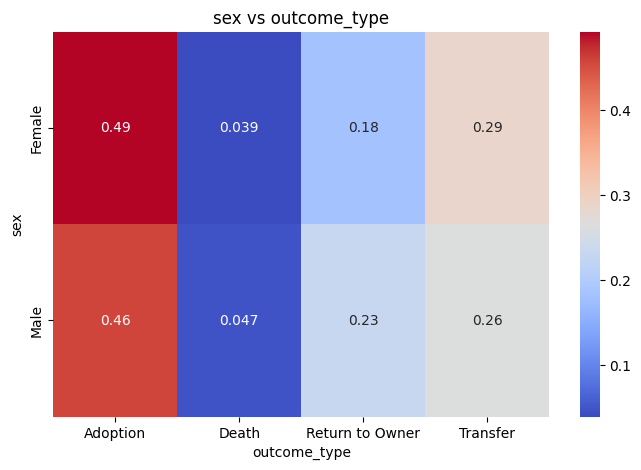

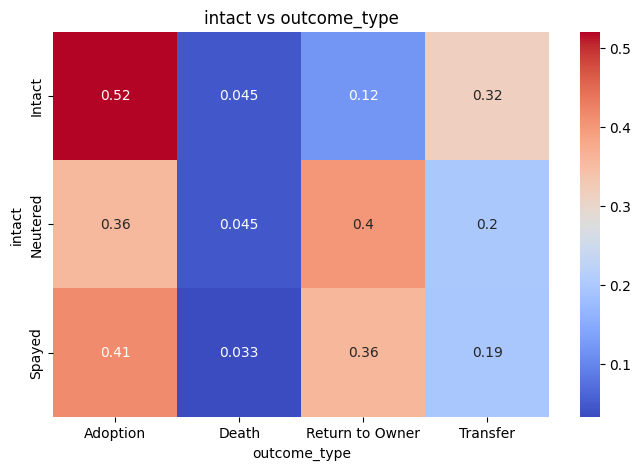

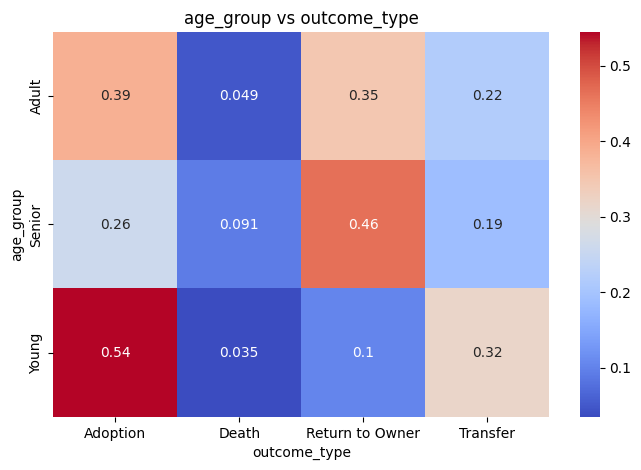

In [74]:
#jaki procent przypadków kończy się danym outcome 
scores = {}
for col in cat_cols:
    crosstab = pd.crosstab(df[col], df["outcome_type"], normalize="index")
    plt.figure(figsize=(8,5))
    sns.heatmap(crosstab, annot=True, cmap="coolwarm")
    plt.title(f"{col} vs outcome_type")
    plt.show()

#outcome_subtype, sex_upon_outcome - opisuje outcome

#animal_type - dzikie zwierzęta prawie zawsze death
#cat i dog mają podobne szanse na adopcje, koty częściej transfer
#psy częściej wracają do właścicieli


#intake_condition - zdrowe zwierzęta częsciej adoptowane 
#chore, zranione zwierzęta często giną 
#nursing - karmiące trafiają do transfer 
#właściciele rzadko odbierają chore zwierzęta

#intake_type - dzikie, euthanasia_request prawie zawsze giną 
#zwierzęta oddane przez właściciela mają większą szansę na adopcje
#public assist czesto się kończa zwrotem do włascicieli 
#bezpańskie rozkładają się między adopcję i transfer

#age_upon_intake_age_group - najmłodsze częsciej adoptowane, 
#wraz z wiekiem adopcja spada, ale rto wzrasta prawie zawsze ma właściciela

#bat - wildlife, zawsze giną, labrador retriever czesto adoptowany
#pitbulle wracają do wlascicieli, ale też adoptowane porównywalne 
#koty mają wysoki transfer

#samice trochę częsciej adoptowane niż samce, zwierzęta o nieznanej płci prawie 
#zawsze giną

#intact - niewykastrowane są często adoptowane, a wykastrowane częsciej wracają do
#właściciela 


#usunąć takie dane z unknown, euthanasia request i wildlife

<Axes: xlabel='month'>

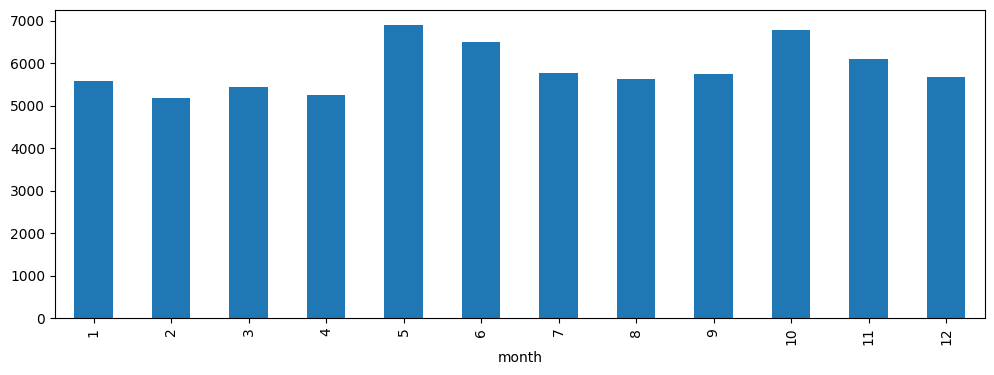

In [75]:
#średnia przyjęć na miesiąc
df.groupby("month").size().plot(kind="bar", figsize=(12,4))

#brak dużych skoków, trendu rosnącego, malejącej
#jedynie lekkie spadki w lutym, kwietniu, wzrosty w maju i w październiku

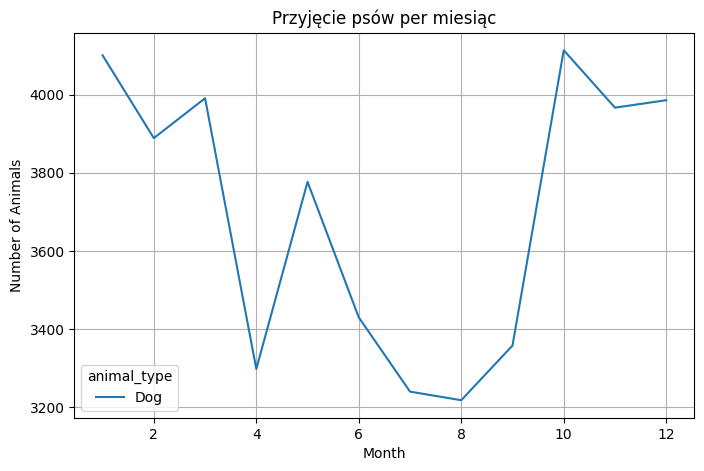

In [76]:

dogs = df[df["animal_type"]=="Dog"]
monthly = pd.crosstab(
    dogs["month"],
    dogs["animal_type"]
)

monthly.plot(kind="line", figsize=(8,5))

plt.title("Przyjęcie psów per miesiąc")
plt.xlabel("Month")
plt.ylabel("Number of Animals")
plt.grid(True)
plt.show()

Text(0, 0.5, 'Count')

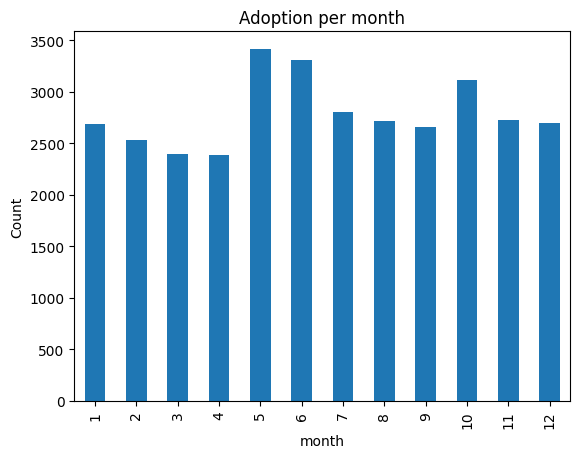

In [78]:
adoptions = df[df["outcome_type"] == "Adoption"]
adoptions.groupby("month").size().plot(kind="bar")

plt.title("Adoption per month")
plt.ylabel("Count")

<Axes: xlabel='year'>

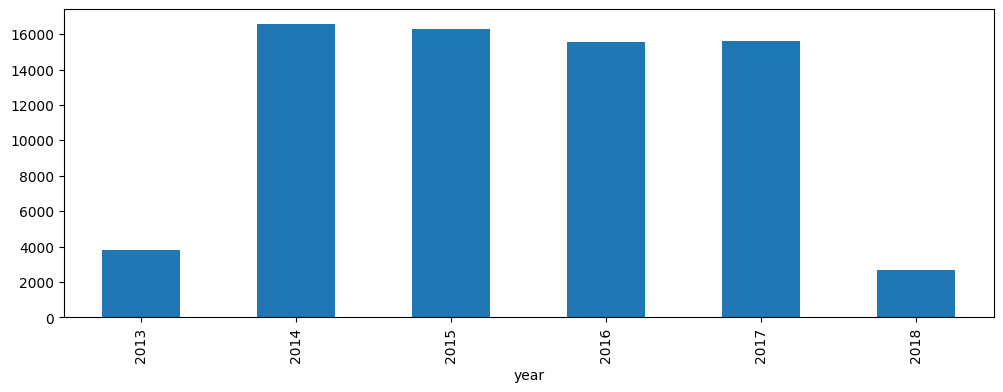

In [79]:
#liczba zwierzat przyjętych per rok
df.groupby("year").size().plot(kind="bar", figsize=(12,4))

#2013 i 2018 są niepełne dane, 2013 zaczyna się od października, a 2018 kończy się w marcu
#jeśli chodzi o liczbę przyjęć to nie ma dużych róznicy jeśli chodzi o 2014-2017

In [80]:
df["intake_date"] = pd.to_datetime(df["intake_datetime"]).dt.date
print(f"Najstarsza data: {df['intake_date'].min()}")
print(f"Najnowsza data: {df['intake_date'].max()}")

Najstarsza data: 2013-10-01
Najnowsza data: 2018-03-29


<Axes: xlabel='year'>

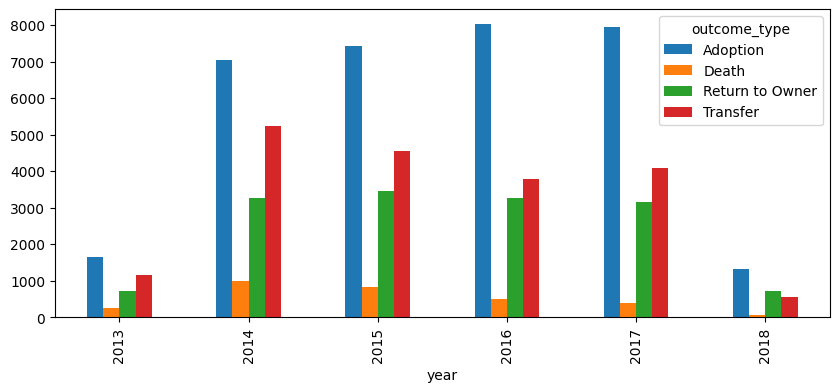

In [81]:
df.groupby(["year", "outcome_type"]).size().unstack(fill_value=0).plot(kind="bar", figsize=(10,4))

#jeśli chodzi o rozkład outcome to ona co roku jest na bardzo zbliżonym poziomie, adoption to tak czy siak trenduje

<Axes: xlabel='month'>

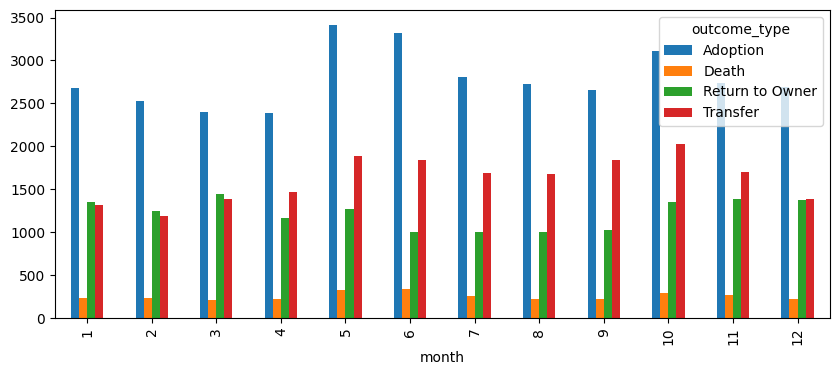

In [82]:
df.groupby(["month", "outcome_type"]).size().unstack(fill_value=0).plot(kind="bar", figsize=(10,4))